# Frozen official-test evaluation
Models and rejection threshold were frozen before one final evaluation. Re-running this notebook reads saved results; it does not retest or tune. Macro metrics give each class equal weight.

In [1]:
from pathlib import Path
import json, sys
import pandas as pd
from IPython.display import display, Image
root=Path.cwd()
if root.name != "ml": root=root/"ml"
assert Path(sys.executable).resolve()==(root/".venv/Scripts/python.exe").resolve()
sys.path.insert(0,str(root))
def read(path): return json.loads((root/path).read_text())


In [2]:
final=read("artifacts/evaluation/final_test_evaluation.json")
display(pd.DataFrame(final["summary"]).T)
print("Acceptance:",final["rejection"])
print("The SVM outperformed the CNN on this official test set.")

,accuracy,macro_precision,macro_recall,macro_f1,noise_recall,noise_support,chords_predicted_as_noise_rate,n_recordings
svm,0.904762,0.930190,0.906667,0.899782,1.000000,3.0,0.0,147.0
cnn,0.877551,0.874589,0.873333,0.859119,0.666667,3.0,0.0,147.0


Acceptance: {'accepted': 139, 'coverage': 0.9455782312925171, 'accuracy_on_accepted': 0.8705035971223022, 'status_counts': {'ok': 139, 'uncertain': 0, 'noise': 2, 'silence': 0, 'unsupported': 6}}
The SVM outperformed the CNN on this official test set.


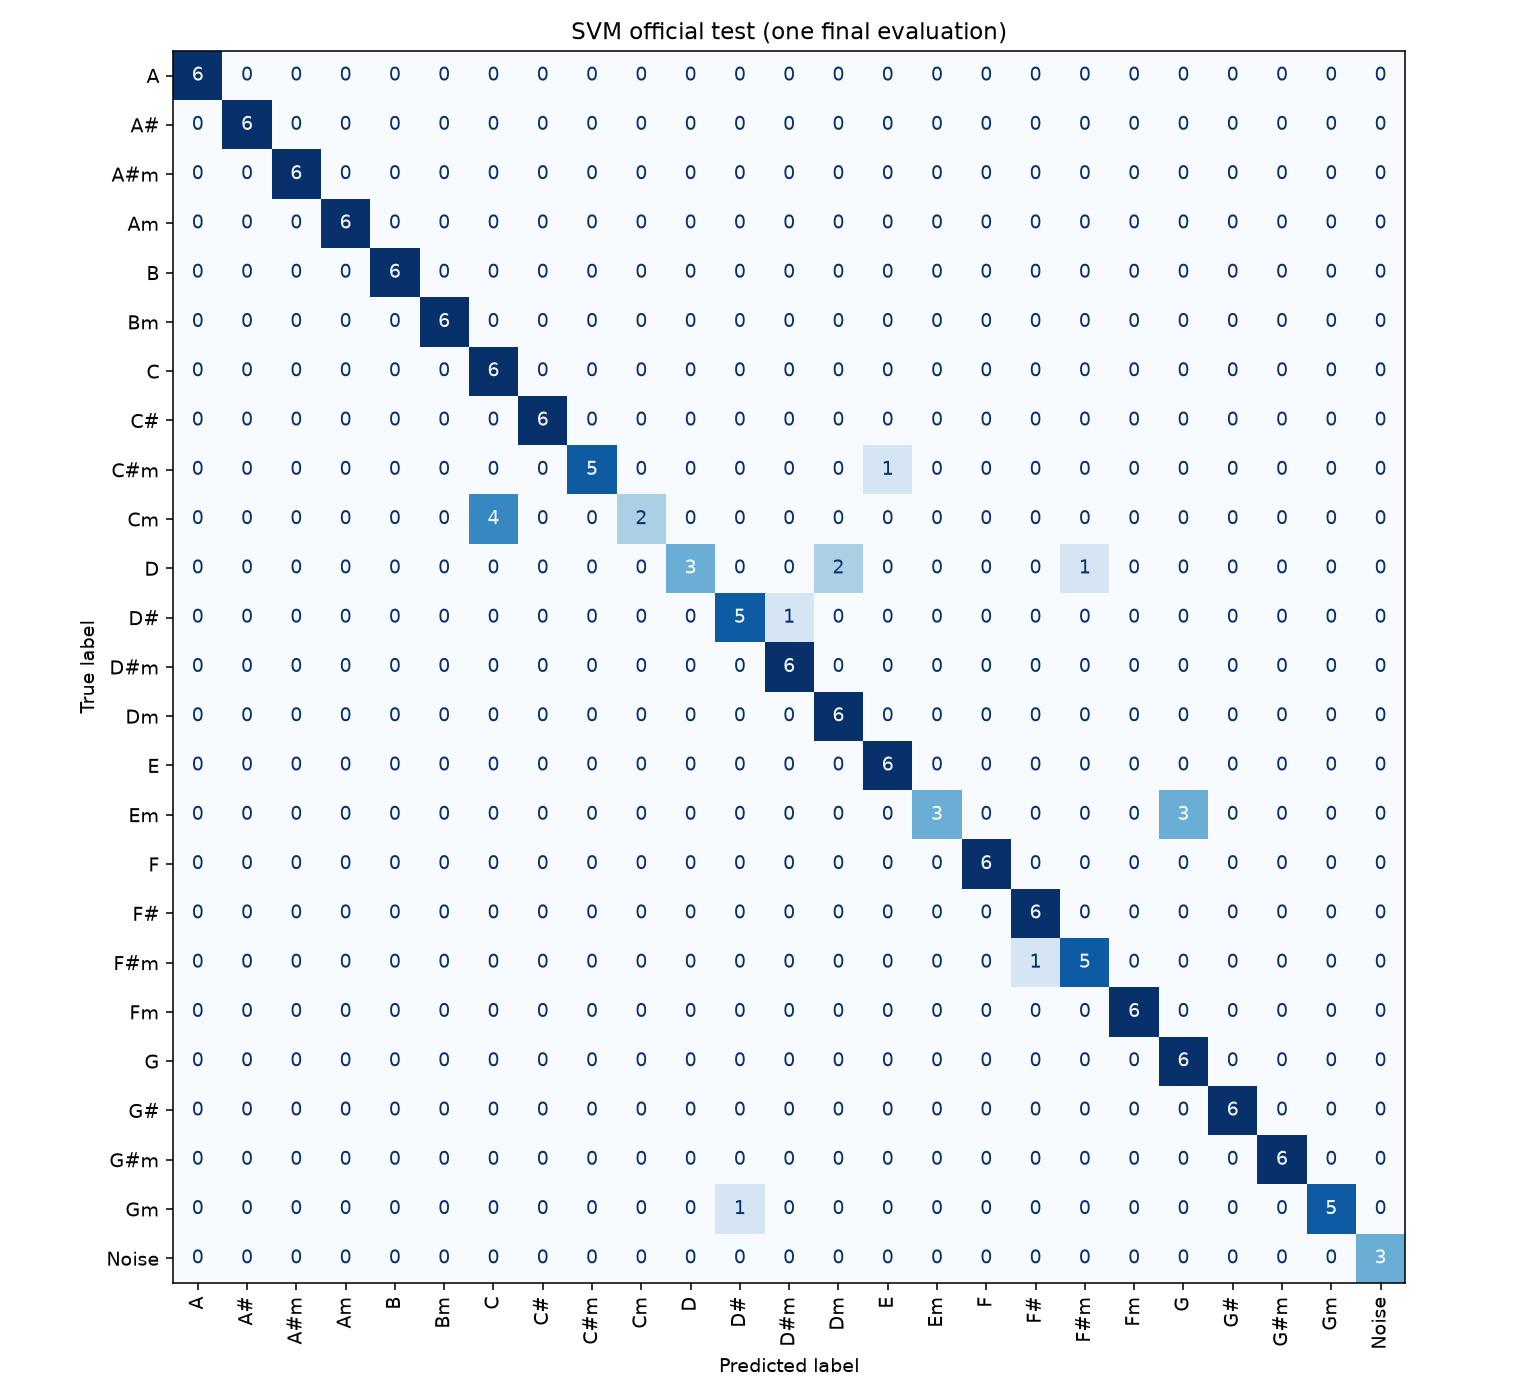

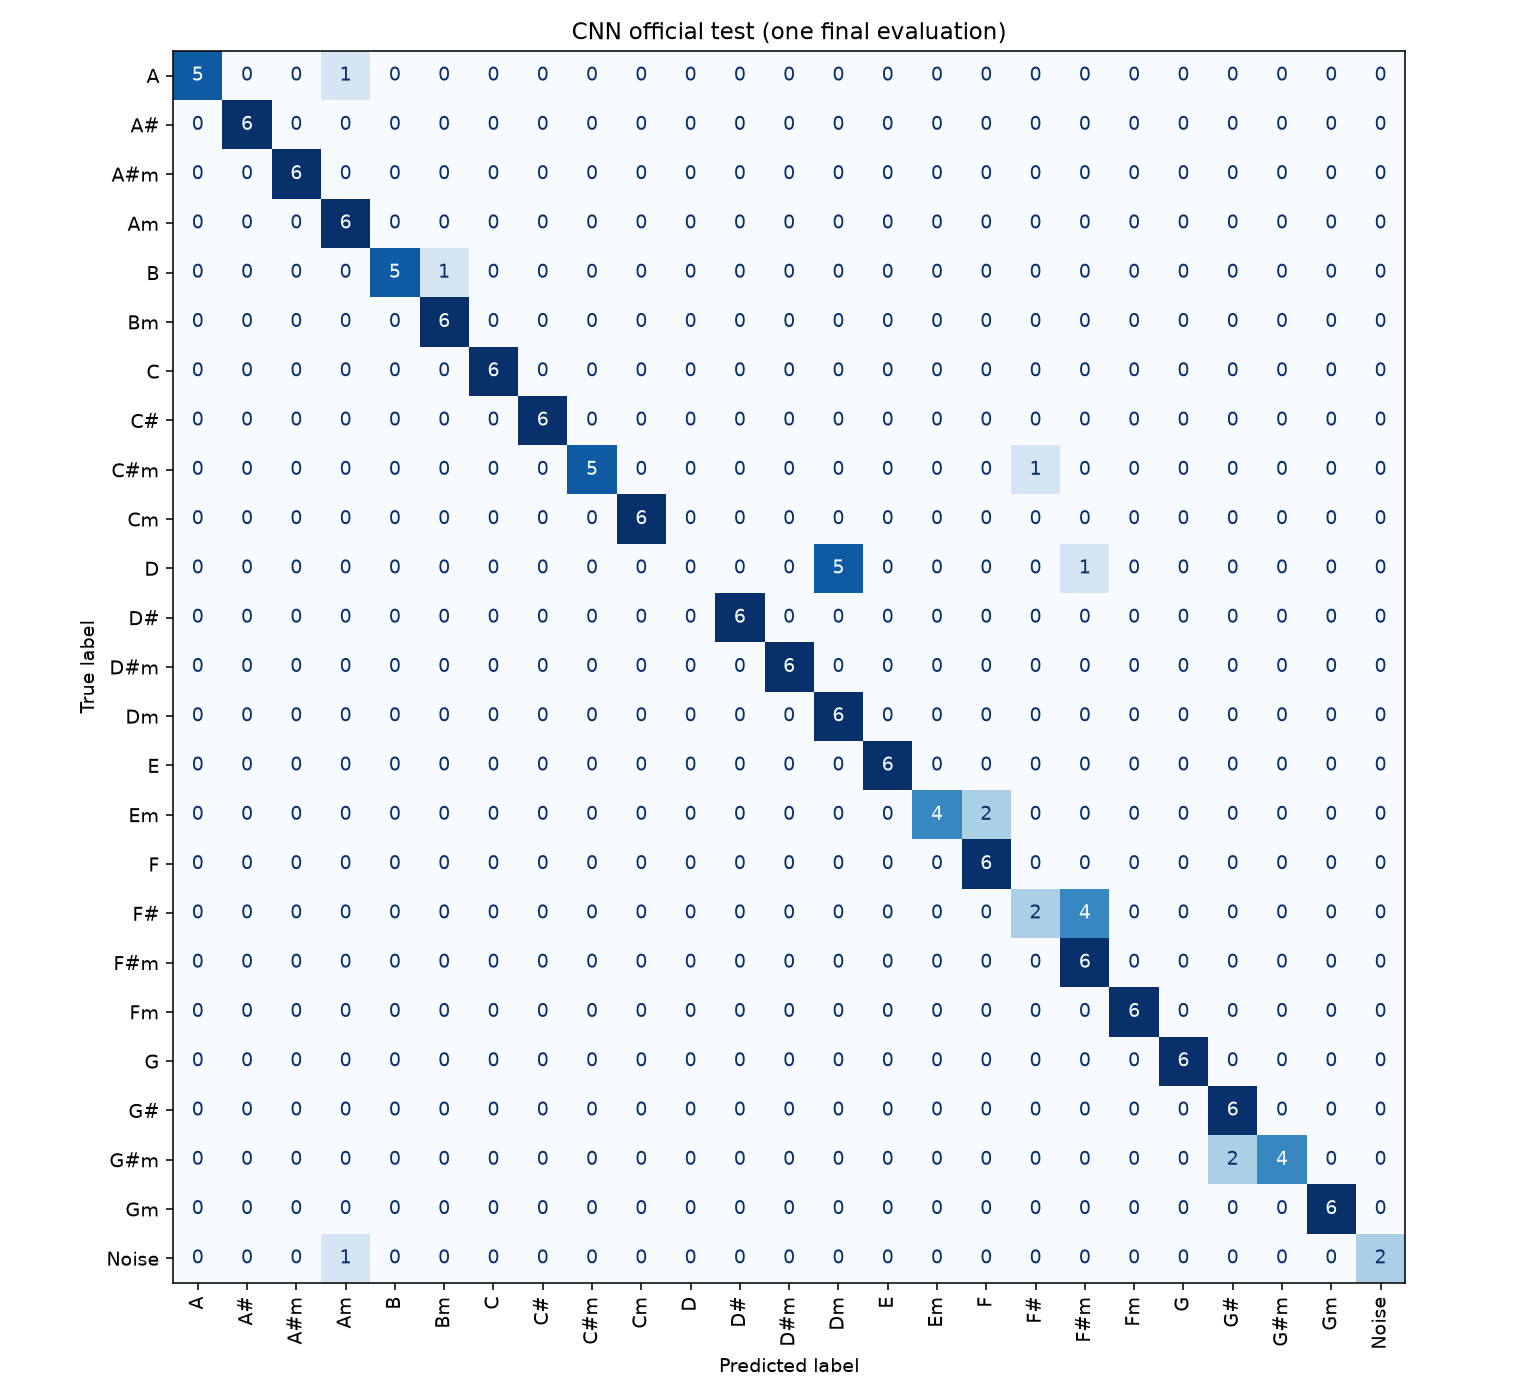

,actual,predicted,score
0,A,Am,0.618816
1,B,Bm,0.612732
2,C#m,F#,0.720460
3,D,Dm,0.464732
4,D,Dm,0.599386
5,D,F#m,0.561186
6,D,Dm,0.551022
7,D,Dm,0.993729
8,D,Dm,0.850036
9,Em,F,0.654721


In [3]:
for model in ["svm","cnn"]:
    display(Image(filename=str(root/f"artifacts/evaluation/{model}_test_metrics.png")))
errors=[{"actual":r["actual"],"predicted":r["predicted_class"],"score":r["model_score"]} for r in final["predictions"] if r["actual"]!=r["predicted_class"]]
display(pd.DataFrame(errors))

## Interpretation and next independent test
The CNN misses every test D and often confuses F# with F#m. Diagnostic chroma still distinguishes the expected major/minor thirds; do not relabel test audio based on model mistakes. The exact cause needs independent investigation. Noise support is only three files. A validation-selected score threshold did not reject test mistakes adequately. Scores are uncalibrated, and a different guitar/microphone may perform worse.

Collect personal recordings as a separate holdout and run `evaluate_personal.py`. Save the initial results before discussing data collection/fine-tuning. Physical microphone and rendered browser verification are pending because the UI automation host was unavailable.

In [4]:
display(read("artifacts/cnn/rejection.json")["validation_selection"])
for limitation in final["limitations"]: print("-",limitation)

{'threshold': 0.3,
 'accepted': 126,
 'accuracy_on_accepted': 0.9920634920634921,
 'coverage': 0.9921259842519685}

- Only 3 Noise examples per official split: noise metrics have high uncertainty.
- Am and E each include 15 GarageBand files, explaining 40 rather than 25 training examples.
- Fender source is a single guitar/player; filename take numbers do not establish independent recording sessions.
- Exact PCM hashing detects duplicates, not all related or nearly identical takes.
- Official test waveforms are inspected for integrity only; EDA figures and choices use training audio.
- Threshold fitted on a small reused validation split; scores are not calibrated.
- Clipped source recordings retained and reported; no personal guitar generalization results yet.
